# 02 – Feature engineering, training & tracking
Thin wrapper over `python -m heart_risk.train` – the notebook exists for exploration; the script is what CI runs.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]
import os

os.chdir(ROOT)

In [2]:
from heart_risk.data import load_processed, split_xy
from heart_risk.features import build_preprocessor

X, y = split_xy(load_processed())
pre = build_preprocessor().fit(X)
print(len(pre.get_feature_names_out()), "model features:")
list(pre.get_feature_names_out())

24 model features:


['age',
 'trestbps',
 'chol',
 'thalach',
 'oldpeak',
 'ca',
 'hr_reserve_ratio',
 'age_chol_index',
 'sex',
 'fbs',
 'exang',
 'cp_1.0',
 'cp_2.0',
 'cp_3.0',
 'cp_4.0',
 'restecg_0.0',
 'restecg_1.0',
 'restecg_2.0',
 'slope_1.0',
 'slope_2.0',
 'slope_3.0',
 'thal_3.0',
 'thal_6.0',
 'thal_7.0']

Preprocessing = `ClinicalFeatureBuilder` (2 engineered features) → median-impute + standard-scale numerics, mode-impute binaries, mode-impute + one-hot categoricals.

In [3]:
from heart_risk import train

meta = train.main([])  # full grid search for all three model families, logged to ./mlruns

2026-10-17 02:28:58,101 INFO heart_risk.train: Train (242, 13) / test (61, 13), positive rate 0.46


/Users/bhargava/Downloads/assignment/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/bhargava/Downloads/assignment/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/bhargava/Downloads/assignment/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitaliz

/Users/bhargava/Downloads/assignment/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/bhargava/Downloads/assignment/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/bhargava/Downloads/assignment/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitaliz

2026/10/17 02:29:01 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026-10-17 02:29:01,662 INFO heart_risk.train: logistic_regression  cv_roc_auc=0.906±0.020 test_roc_auc=0.957 test_acc=0.885 (2.0s)


...

2026/10/17 02:29:10 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'heart-risk-classifier' already exists. Creating a new version of this model...
Created version '2' of model 'heart-risk-classifier'.
/Users/bhargava/Downloads/assignment/.venv/lib/python3.11/site-packages/mlflow/types/utils.py:407: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/10/17 02:29:11 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026-10-17 02:29:11,950 INFO heart_risk.train: Saved model -> /Users/bhargava/Downloads/assignment/models/heart_risk_model.joblib


               name  cv_accuracy_mean  cv_precision_mean  cv_recall_mean  cv_f1_mean  cv_roc_auc_mean  cv_accuracy_std  cv_precision_std  cv_recall_std  cv_f1_std  cv_roc_auc_std  test_accuracy  test_precision  test_recall  test_f1  test_roc_auc
logistic_regression             0.855              0.861           0.828       0.840            0.906            0.030             0.075          0.054      0.030           0.020          0.885           0.818        0.964    0.885         0.957
      random_forest             0.826              0.852           0.765       0.799            0.898            0.017             0.057          0.094      0.033           0.028          0.885           0.839        0.929    0.881         0.953
  gradient_boosting             0.802              0.802           0.774       0.781            0.880            0.018             0.075          0.077      0.018           0.026          0.885           0.862        0.893    0.877         0.949


In [4]:
import pandas as pd

pd.read_csv("reports/model_comparison.csv").set_index("name").filter(like="_mean").T.round(3)

name,logistic_regression,random_forest,gradient_boosting
cv_accuracy_mean,0.855,0.826,0.802
cv_precision_mean,0.861,0.852,0.802
cv_recall_mean,0.828,0.765,0.774
cv_f1_mean,0.840,0.799,0.781
cv_roc_auc_mean,0.906,0.898,0.880


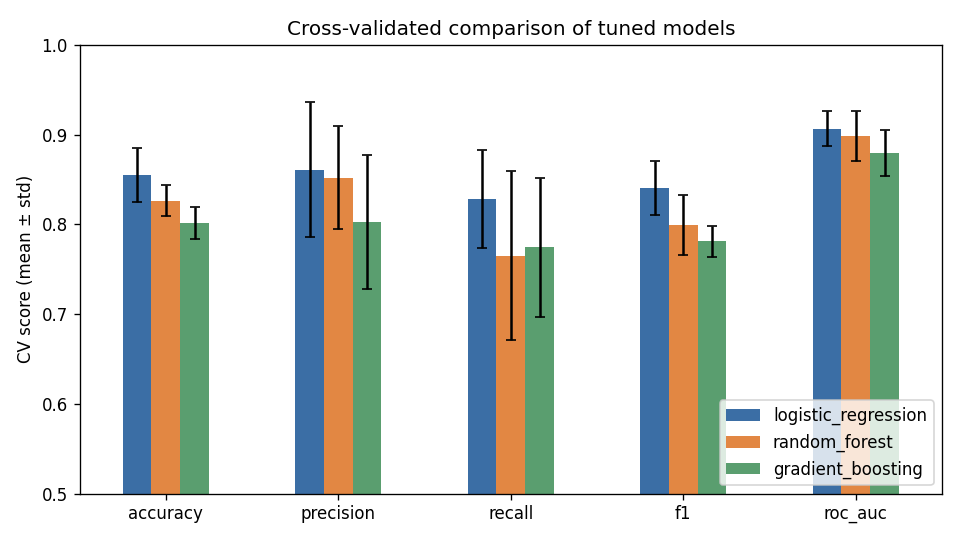

In [5]:
from IPython.display import Image

Image("reports/figures/training/model_comparison.png")

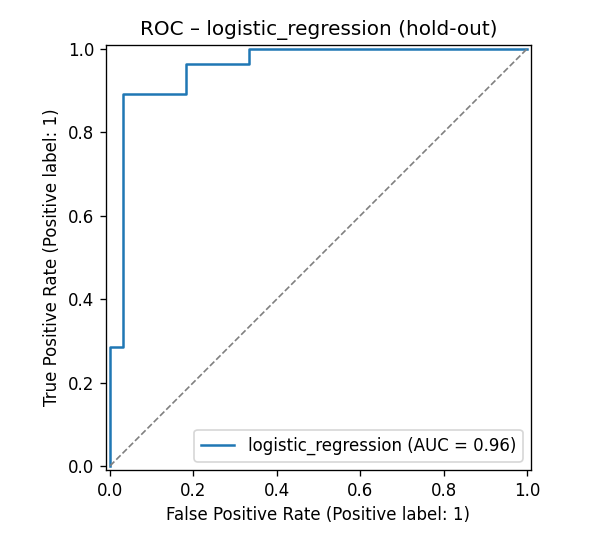

In [6]:
Image(f"reports/figures/training/roc_{meta['model_name']}.png")

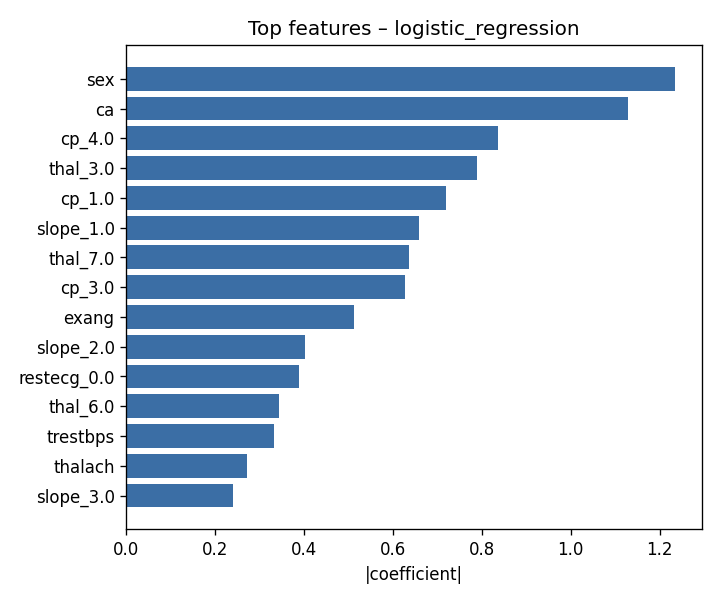

In [7]:
Image(f"reports/figures/training/importance_{meta['model_name']}.png")

In [8]:
import mlflow

mlflow.set_tracking_uri("file:./mlruns")
runs = mlflow.search_runs(experiment_names=["heart-disease-risk"])
runs[["tags.mlflow.runName", "metrics.cv_roc_auc_mean", "metrics.test_roc_auc", "metrics.test_recall"]].round(3)

,tags.mlflow.runName,metrics.cv_roc_auc_mean,metrics.test_roc_auc,metrics.test_recall
0,final_logistic_regression,0.906,0.957,0.964
1,gradient_boosting,0.880,0.949,0.893
2,random_forest,0.898,0.953,0.929
3,logistic_regression,0.906,0.957,0.964
4,final_logistic_regression,0.906,0.957,0.964
5,gradient_boosting,0.880,0.949,0.893
6,random_forest,0.898,0.953,0.929
7,logistic_regression,0.906,0.957,0.964
